# Task 2 — Proposed GNN: EMG-CorrGCN (Exercise B, 17 gestures)
This notebook covers: (A) graph construction, (B) architecture diagram, (C) explanation + settings, training and testing of the proposed network,
learning curves, first results against the baselines, per-gesture comparison, inference time and model size.

# 1. Data loading and subject split

In [1]:
# 1. SETUP
import os, re, glob, warnings
import numpy as np, pandas as pd, scipy.io as sio
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from scipy.stats import skew, kurtosis
import plotly.express as px
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")

DATA_ROOT = os.environ.get("NINAPRO_ROOT", "/kaggle/input")
FS, WIN, SEED = 2000, 400, 42          # 2000 Hz, window = 400 samples (200 ms)
rng = np.random.default_rng(SEED)
CH = [f"ch{i:02d}" for i in range(1, 13)]

In [2]:
# 2. FIND FILES
pat = re.compile(r"S(\d+)_E(\d+)_A\d+\.mat$")
paths = sorted(glob.glob(f"{DATA_ROOT}/**/S*_E*_A*.mat", recursive=True))
files = pd.DataFrame([(p, int(m[1]), int(m[2])) for p in paths if (m := pat.search(p))],
                     columns=["path", "subject", "exercise"])
assert len(files) > 0, "No .mat files found"

print(f"Files: {len(files)} | Subjects: {files.subject.nunique()} | Exercises: {sorted(files.exercise.unique().tolist())}")
print(f"12 EMG channels, {FS} Hz, window = {WIN} samples = {WIN*1000//FS} ms")

Files: 120 | Subjects: 40 | Exercises: [1, 2, 3]
12 EMG channels, 2000 Hz, window = 400 samples = 200 ms


In [3]:
# 3. LOAD EVERYTHING ONCE (one file at a time, to save memory)
samples, wins, segs, n_bad, n_total = [], [], [], 0, 0

for f in files.itertuples():
    m = sio.loadmat(f.path, variable_names=["emg", "restimulus", "rerepetition"])
    emg = m["emg"].astype(np.float32)
    lab, rep = m["restimulus"].ravel(), m["rerepetition"].ravel()
    n_bad += int((~np.isfinite(emg)).sum()); n_total += emg.size

    # 4000 random raw samples (for stats + plots)
    s = pd.DataFrame(emg[rng.choice(len(emg), min(4000, len(emg)), replace=False)], columns=CH)
    s["subject"] = f.subject 
    samples.append(s)

    # one segment = one gesture in one repetition
    cut = np.flatnonzero((np.diff(lab) != 0) | (np.diff(rep) != 0)) + 1
    for a, b in zip(np.r_[0, cut], np.r_[cut, len(lab)]):
        segs.append((f.subject, f.exercise, int(lab[a]), b - a))
        if lab[a] > 0 and b - a >= WIN:                      # active gesture -> take 1 random window
            st = rng.integers(a, b - WIN + 1)
            wins.append((f.subject, f.exercise, int(lab[a]), np.sqrt((emg[st:st+WIN] ** 2).mean(0))))  # RMS per channel

samp = pd.concat(samples, ignore_index=True)
seg = pd.DataFrame(segs, columns=["subject", "exercise", "label", "length"])
win = pd.DataFrame([w[:3] for w in wins], columns=["subject", "exercise", "label"])
rms = pd.DataFrame([w[3] for w in wins], columns=CH)        # window feature = RMS of each channel

print(f"Loaded {len(files)} files, {n_total/12:,.0f} samples per channel")
print(f"Segments: {len(seg):,} | Windows used for analysis: {len(win):,} (RMS feature, 12 channels)")

Loaded 120 files, 207,713,115 samples per channel
Segments: 23,640 | Windows used for analysis: 11,760 (RMS feature, 12 channels)


In [4]:
# 4. SPLIT SUBJECTS (train / val / test) - do this BEFORE fitting anything
subj = rng.permutation(sorted(win.subject.unique()))
n_test, n_val = max(1, round(0.2 * len(subj))), max(1, round(0.1 * len(subj)))
test, val, train = subj[:n_test], subj[n_test:n_test + n_val], subj[n_test + n_val:]
assert not set(train) & set(val) and not set(train) & set(test) and not set(val) & set(test)

is_train = win.subject.isin(train).values
print("[OK] No subject appears in two groups (no leakage)")
print(f"train: {len(train)} subjects | val: {len(val)} subjects | test: {len(test)} subjects")
print(f"windows -> train: {is_train.sum():,} | val: {win.subject.isin(val).sum():,} | test: {win.subject.isin(test).sum():,}")
print("Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.")

# train-only views: every statistic / plot / fitted object in A-H comes from these
split    = np.where(is_train, "train", np.where(win.subject.isin(val), "val", "test"))
samp_tr  = samp[samp.subject.isin(train)][CH]       # raw samples, train subjects
win_tr   = win[is_train]                            # window labels, train subjects
rms_tr   = rms[is_train]                            # RMS features, train subjects
seg_tr   = seg[seg.subject.isin(train)]             # segments, train subjects

[OK] No subject appears in two groups (no leakage)
train: 28 subjects | val: 4 subjects | test: 8 subjects
windows -> train: 8,232 | val: 1,176 | test: 2,352
Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.


In [5]:
# quick look at the structure we just described
per_subj = win.groupby("subject").size()
print(f"Subjects: {win.subject.nunique()} | windows per subject: min {per_subj.min()}, mean {per_subj.mean():.0f}, max {per_subj.max()}")
print(f"Graph per sample: {len(CH)} nodes (one per electrode), 1 feature per node (window RMS)")
display(win.assign(split=split).groupby("split").agg(subjects=("subject", "nunique"), windows=("label", "size"), gestures=("label", "nunique")))

Subjects: 40 | windows per subject: min 294, mean 294, max 294
Graph per sample: 12 nodes (one per electrode), 1 feature per node (window RMS)


,subjects,windows,gestures
split,,,
test,8,2352,49
train,28,8232,49
val,4,1176,49


# 2. Exercise B data 

In [6]:
# Exercise B data (exercise 1 in DB2), same subject split as Task 1
from sklearn.preprocessing import LabelEncoder

mB = (win.exercise == 1).values
X  = np.log(rms.values[mB] + 1e-9)                 # log fixes skew
le = LabelEncoder(); y = le.fit_transform(win.label.values[mB])   # 0..16
sp = split[mB]
tr, va, te = sp == "train", sp == "val", sp == "test"

scaler = StandardScaler().fit(X[tr])               # fit on TRAIN only
Xtr, Xva, Xte = scaler.transform(X[tr]), scaler.transform(X[va]), scaler.transform(X[te])
ytr, yva, yte = y[tr], y[va], y[te]

print(f"Exercise B: {len(y)} windows, {len(le.classes_)} classes")
print(f"train {len(ytr)} | val {len(yva)} | test {len(yte)}  (subject-wise, no leakage)")
print(f"class count per class (train): min {np.bincount(ytr).min()}, max {np.bincount(ytr).max()}")
print(f"random guess accuracy = {1/len(le.classes_):.3f}")
s_te = set(win.subject.values[mB][te])          # test subjects (used in the verdict text below)

Exercise B: 4080 windows, 17 classes
train 2856 | val 408 | test 816  (subject-wise, no leakage)
class count per class (train): min 168, max 168
random guess accuracy = 0.059


In [7]:
import time
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

# 3. Baseline results (loaded from the baselines notebook)

In [8]:
def find(name):
    for path in [name, f"/kaggle/working/{name}"] + glob.glob(f"/kaggle/input/**/{name}", recursive=True):
        if os.path.exists(path): return path
    raise FileNotFoundError(f"{name} not found. Run the baselines notebook first (see the top of this notebook).")

results = pd.read_csv(find("baseline_results.csv"), index_col=0)
cost    = pd.read_csv(find("baseline_cost.csv"), index_col=0)
saved   = np.load(find("baseline_preds.npz"))
assert np.array_equal(saved["y_test"], yte), "Baseline predictions belong to a different test set"
preds = {k: saved[k] for k in saved.files if k != "y_test"}
best_name = results.macro_f1.idxmax()

display(results.round(3))
print(f"Baseline to beat: {best_name} (test macro-F1 = {results.macro_f1.max():.3f})")

,val_acc,accuracy,balanced_acc,precision_macro,recall_macro,macro_f1,train_time_s
model,,,,,,,
Random Forest,0.240,0.196,0.196,0.202,0.196,0.182,2.135
SVM (RBF),0.245,0.189,0.189,0.203,0.189,0.180,0.622
Logistic Regression,0.289,0.194,0.194,0.196,0.194,0.176,0.111
Gradient Boosting,0.255,0.183,0.183,0.188,0.183,0.173,10.699
MLP,0.279,0.184,0.184,0.179,0.184,0.168,1.109
k-NN,0.179,0.159,0.159,0.200,0.159,0.157,0.008
Decision Tree,0.150,0.136,0.136,0.127,0.136,0.126,0.074


Baseline to beat: Random Forest (test macro-F1 = 0.182)


# GNN proposal
## (A) Graph construction

| Item | Our choice |
|---|---|
| Graph | one small graph for every 200 ms window |
| Nodes | the 12 sEMG electrodes (ch01 ... ch12) |
| Node feature | log RMS of that electrode, standardised with the train scaler (1 value per node) |
| Edges | each electrode is connected to its 3 most correlated electrodes (top-3), graph made symmetric, self-loops added |
| Edge weight | absolute Pearson correlation \|r\| between two channels, computed on TRAIN windows only |
| Normalisation | A_hat = D^-1/2 (A + I) D^-1/2 |

**Why it fits:** a gesture activates a pattern of forearm muscles, not a single channel. Electrodes close to the same muscle give correlated signals,
so connecting them lets the model combine information from related electrodes while still treating every electrode as its own node.
The graph is the same for all samples and is built from training data only, so there is no leakage.

In [9]:
# (A) graph construction - TRAIN data only
K = 3
R = np.abs(np.corrcoef(Xtr.T)); np.fill_diagonal(R, -1)
A = np.zeros((12, 12))
for i in range(12):
    nb = np.argsort(-R[i])[:K]; A[i, nb] = R[i, nb]     # top-3 neighbours, weight = |r|
A = np.maximum(A, A.T) + np.eye(12)                     # symmetric + self loops
d = A.sum(1); A_hat = A / np.sqrt(np.outer(d, d))       # D^-1/2 A D^-1/2
print("edges (without self loops):", int((A > 0).sum() - 12) // 2)

edges (without self loops): 26


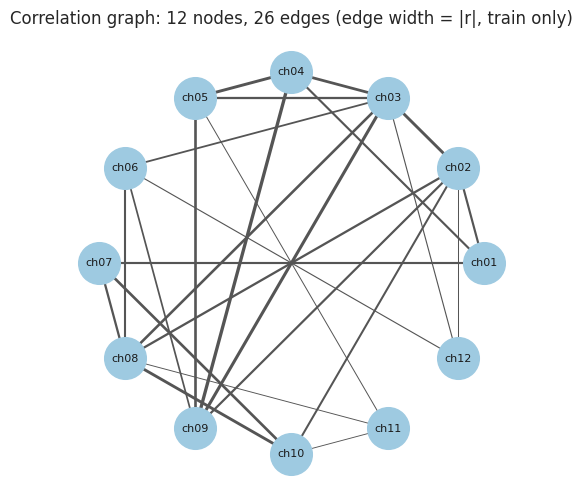

In [10]:
# draw the graph that EMG-CorrGCN uses (A comes from the training cell above)
A_plain = A - np.eye(12)                                         # remove self-loops for drawing
G = nx.relabel_nodes(nx.from_numpy_array(A_plain), {i: CH[i] for i in range(12)})
w = [G[u][v]["weight"] for u, v in G.edges]
plt.figure(figsize=(6, 6))
nx.draw_networkx(G, nx.circular_layout(G), node_color="#9ecae1", node_size=900, font_size=8,
                 width=[3 * x for x in w], edge_color="#555")
plt.title(f"Correlation graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges (edge width = |r|, train only)")
plt.axis("off"); plt.show()

## (B) Architecture diagram

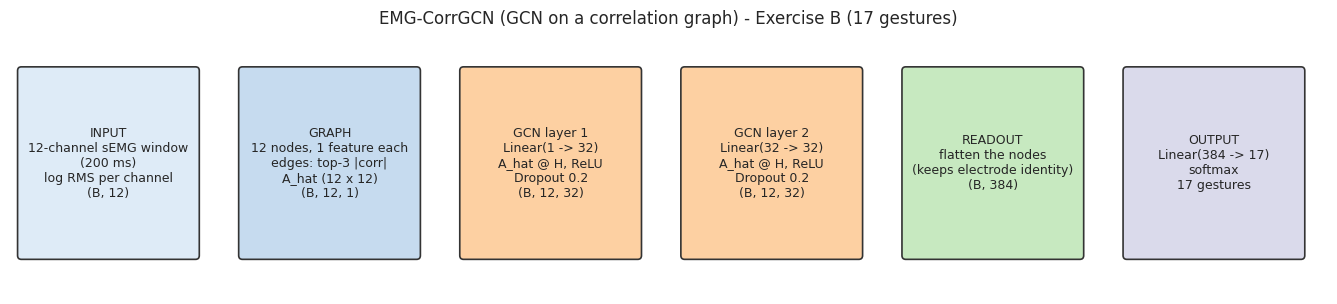

In [11]:
from matplotlib.patches import FancyBboxPatch

steps = [
    ("INPUT\n12-channel sEMG window\n(200 ms)\nlog RMS per channel\n(B, 12)", "#deebf7"),
    ("GRAPH\n12 nodes, 1 feature each\nedges: top-3 |corr|\nA_hat (12 x 12)\n(B, 12, 1)", "#c6dbef"),
    ("GCN layer 1\nLinear(1 -> 32)\nA_hat @ H, ReLU\nDropout 0.2\n(B, 12, 32)", "#fdd0a2"),
    ("GCN layer 2\nLinear(32 -> 32)\nA_hat @ H, ReLU\nDropout 0.2\n(B, 12, 32)", "#fdd0a2"),
    ("READOUT\nflatten the nodes\n(keeps electrode identity)\n(B, 384)", "#c7e9c0"),
    ("OUTPUT\nLinear(384 -> 17)\nsoftmax\n17 gestures", "#dadaeb"),
]
fig, ax = plt.subplots(figsize=(17, 3.4)); ax.axis("off"); ax.set_xlim(0, 17.4); ax.set_ylim(0, 3.4)
bw, gap = 2.3, 0.62
for k, (txt, col) in enumerate(steps):
    x = 0.15 + k * (bw + gap)
    ax.add_patch(FancyBboxPatch((x, 0.5), bw, 2.4, boxstyle="round,pad=0.05", fc=col, ec="#333", lw=1.2))
    ax.text(x + bw / 2, 1.7, txt, ha="center", va="center", fontsize=9)
    if k < len(steps) - 1:
        ax.annotate("", xy=(x + bw + gap - 0.05, 1.7), xytext=(x + bw + 0.05, 1.7), arrowprops=dict(arrowstyle="->", lw=1.8))
ax.set_title("EMG-CorrGCN (GCN on a correlation graph) - Exercise B (17 gestures)", fontsize=12)
plt.show()

## (C) How it works, in plain words, and the settings

Our proposed network is called **EMG-CorrGCN** (EMG Correlation-graph GCN): a graph convolutional network on a correlation graph of the 12 electrodes.

Each 200 ms EMG window becomes a small graph with 12 nodes, one per electrode. A node only carries one number: how active the muscle under that electrode is (log RMS).
In every GCN layer a node first transforms its own value and then mixes it with the values of its connected neighbours, weighted by their correlation.
Two layers mean that information can travel two steps through the graph. At the end we do not average the nodes, because that would hide which electrode was active.
Instead we keep all 12 node vectors side by side (flatten) and a final linear layer gives one score per gesture. The model is trained with cross-entropy,
and the epoch with the best validation accuracy is the one we test.

In [12]:
settings = pd.Series({
    "Proposed network": "EMG-CorrGCN (EMG Correlation-graph GCN)",
    "Task": "17-class gesture recognition, Exercise B, subject-independent",
    "Nodes / node feature": "12 electrodes / log RMS (1 value per node)",
    "Graph": "top-3 |corr| neighbours, symmetric, self-loops, D^-1/2 A D^-1/2, built from train data",
    "GCN layers": "2 x (Linear -> A_hat @ H -> ReLU -> Dropout)",
    "Hidden size / dropout": "32 / 0.2",
    "Readout": "flatten (12 x 32 = 384) -> Linear(384, 17)",
    "Loss / optimiser": "cross-entropy / Adam (lr 5e-3, weight decay 1e-4)",
    "Epochs / batch": "300 / full batch",
    "Model selection": "epoch with the best validation accuracy",
    "Seeds": "5 (0 to 4), mean and std reported",
}, name="setting").to_frame()
display(settings)

,setting
Proposed network,EMG-CorrGCN (EMG Correlation-graph GCN)
Task,"17-class gesture recognition, Exercise B, subj..."
Nodes / node feature,12 electrodes / log RMS (1 value per node)
Graph,"top-3 |corr| neighbours, symmetric, self-loops..."
GCN layers,2 x (Linear -> A_hat @ H -> ReLU -> Dropout)
Hidden size / dropout,32 / 0.2
Readout,"flatten (12 x 32 = 384) -> Linear(384, 17)"
Loss / optimiser,"cross-entropy / Adam (lr 5e-3, weight decay 1e-4)"
Epochs / batch,300 / full batch
Model selection,epoch with the best validation accuracy


# 4. Training and testing the proposed network

# Proposed network: EMG-CorrGCN (EMG Correlation-graph GCN), trained and tested on Exercise B

In [13]:
# EMG-CorrGCN: model + training + testing
import torch, torch.nn as nn

class EMGCorrGCN(nn.Module):
    def __init__(self, A_hat, n_cls, hid=32, p=0.2):
        super().__init__()
        self.register_buffer("A", torch.tensor(A_hat, dtype=torch.float32))
        self.l1, self.l2 = nn.Linear(1, hid), nn.Linear(hid, hid)
        self.out = nn.Linear(12 * hid, n_cls)           # flatten readout keeps electrode identity
        self.drop = nn.Dropout(p)
    def forward(self, x):                               # x: (batch, 12)
        h = x.unsqueeze(-1)                             # node feature: (batch, 12, 1)
        h = self.drop(torch.relu(self.A @ self.l1(h)))  # graph conv 1
        h = self.drop(torch.relu(self.A @ self.l2(h)))  # graph conv 2
        return self.out(h.flatten(1))

T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
xtr, xva, xte = T(Xtr), T(Xva), T(Xte)
ytr_t, yva_t, yte_t = T(ytr, torch.long), T(yva, torch.long), T(yte, torch.long)
print("parameters:", sum(p.numel() for p in EMGCorrGCN(A_hat, len(le.classes_)).parameters()))

def train_model(seed, epochs=300):
    torch.manual_seed(seed)
    m = EMGCorrGCN(A_hat, n_cls=len(le.classes_))
    opt = torch.optim.Adam(m.parameters(), lr=5e-3, weight_decay=1e-4)
    hist, best_val, best_ep, best_state, train_time = [], -1, 0, None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        m.train(); opt.zero_grad()
        nn.functional.cross_entropy(m(xtr), ytr_t).backward(); opt.step()
        train_time += time.time() - t0                  # training time = optimiser steps only
        m.eval(); row = {"epoch": ep}
        with torch.no_grad():                           # loss/accuracy of every split after each epoch
            for nm, x, yy in (("train", xtr, ytr_t), ("val", xva, yva_t), ("test", xte, yte_t)):
                out = m(x)
                row[nm + "_loss"] = nn.functional.cross_entropy(out, yy).item()
                row[nm + "_acc"] = (out.argmax(1) == yy).float().mean().item()
        hist.append(row)
        if row["val_acc"] > best_val:                   # best epoch is chosen on VALIDATION only
            best_val, best_ep = row["val_acc"], ep
            best_state = {k: v.clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state); m.eval()
    with torch.no_grad(): p = m(xte).argmax(1).numpy()  # final TEST prediction of the selected epoch
    return pd.DataFrame(hist), best_ep, best_val, p, train_time

runs, extra_runs, histories, gcn_preds = [], [], [], []
for seed in range(5):
    h, best_ep, v, p, t = train_model(seed)
    histories.append(h); gcn_preds.append(p)
    runs.append({"seed": seed, "val_acc": v, **scores(yte, p), "train_time_s": t})
    extra_runs.append({"seed": seed, "best_epoch": best_ep, "test_loss": h.loc[best_ep - 1, "test_loss"]})
runs = pd.DataFrame(runs).set_index("seed"); extra_runs = pd.DataFrame(extra_runs).set_index("seed")
preds["EMG-CorrGCN (ours)"] = gcn_preds[0]                   # seed 0, used for the per-gesture heatmap
display(pd.concat([runs, extra_runs], axis=1).round(3))
print(f"EMG-CorrGCN test macro-F1: mean {runs.macro_f1.mean():.3f}, std {runs.macro_f1.std():.3f}")

parameters: 7665


,val_acc,accuracy,balanced_acc,precision_macro,recall_macro,macro_f1,train_time_s,best_epoch,test_loss
seed,,,,,,,,,
0,0.213,0.189,0.189,0.186,0.189,0.173,10.641,53,2.789
1,0.218,0.190,0.190,0.179,0.190,0.170,10.593,56,2.792
2,0.221,0.190,0.190,0.184,0.190,0.172,10.785,81,2.790
3,0.218,0.185,0.185,0.187,0.185,0.171,10.695,54,2.801
4,0.218,0.180,0.180,0.188,0.180,0.165,10.518,48,2.773


EMG-CorrGCN test macro-F1: mean 0.170, std 0.003


# Learning curves of EMG-CorrGCN

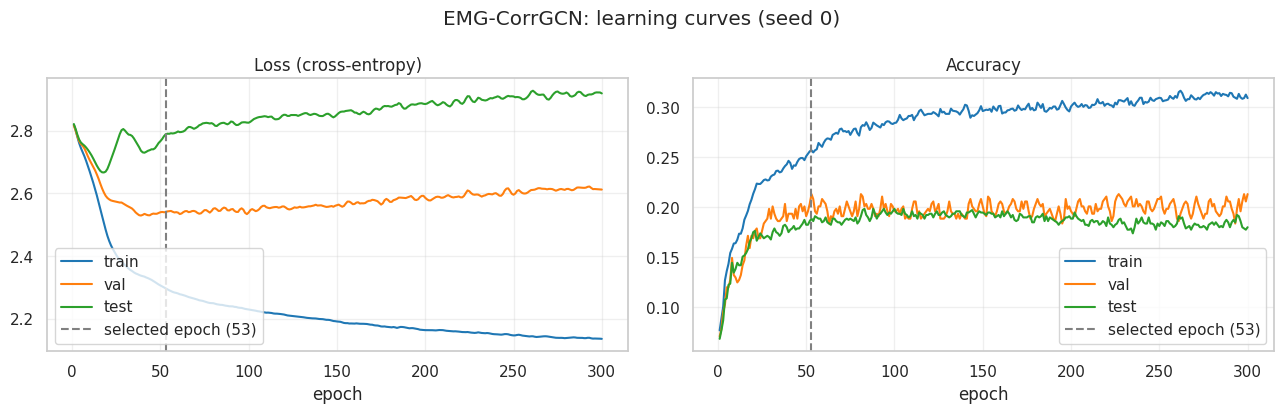

,mean,std
train_loss,2.285,0.019
val_loss,2.536,0.007
test_loss,2.789,0.010
train_acc,0.260,0.009
val_acc,0.218,0.003
test_acc,0.187,0.004


In [14]:
# learning curves (seed 0) + summary of the selected epoch over 5 seeds
h, best_ep = histories[0], extra_runs.best_epoch[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for nm, col in (("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")):
    ax[0].plot(h.epoch, h[nm + "_loss"], color=col, label=nm)
    ax[1].plot(h.epoch, h[nm + "_acc"], color=col, label=nm)
for a, title in zip(ax, ("Loss (cross-entropy)", "Accuracy")):
    a.axvline(best_ep, ls="--", c="gray", label=f"selected epoch ({best_ep})")
    a.set_title(title); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.suptitle("EMG-CorrGCN: learning curves (seed 0)"); plt.tight_layout(); plt.show()

cols = ["train_loss", "val_loss", "test_loss", "train_acc", "val_acc", "test_acc"]
sel = pd.DataFrame([hh.loc[b - 1, cols] for hh, b in zip(histories, extra_runs.best_epoch)])
display(pd.DataFrame({"mean": sel.mean(), "std": sel.std()}).round(3))

# 5. First results: EMG-CorrGCN vs baselines

In [15]:
base = results.drop(index="EMG-CorrGCN (ours)", errors="ignore")         # baselines only
final = base.copy()
final.loc["EMG-CorrGCN (mean of 5 seeds)"] = runs.mean()
display(final.sort_values("macro_f1", ascending=False).round(3))

best_base, best_f1 = base.macro_f1.idxmax(), base.macro_f1.max()
g_mean, g_std = runs.macro_f1.mean(), runs.macro_f1.std()
print(f"Baseline to beat: {best_base} (test macro-F1 = {best_f1:.3f})")
print(f"EMG-CorrGCN: {g_mean:.3f} +- {g_std:.3f}")
if g_mean - g_std > best_f1:   print("Verdict: EMG-CorrGCN is better than the best baseline.")
elif g_mean + g_std < best_f1: print("Verdict: EMG-CorrGCN is worse than the best baseline.")
else:                          print("Verdict: no clear difference (the gap is inside the seed noise).")
print(f"Random guess = {1/len(le.classes_):.3f}. The test set has only {len(s_te)} subjects, so gaps of 1-2 points are not reliable.")

,val_acc,accuracy,balanced_acc,precision_macro,recall_macro,macro_f1,train_time_s
model,,,,,,,
Random Forest,0.240,0.196,0.196,0.202,0.196,0.182,2.135
SVM (RBF),0.245,0.189,0.189,0.203,0.189,0.180,0.622
Logistic Regression,0.289,0.194,0.194,0.196,0.194,0.176,0.111
Gradient Boosting,0.255,0.183,0.183,0.188,0.183,0.173,10.699
EMG-CorrGCN (mean of 5 seeds),0.218,0.187,0.187,0.185,0.187,0.170,10.647
MLP,0.279,0.184,0.184,0.179,0.184,0.168,1.109
k-NN,0.179,0.159,0.159,0.200,0.159,0.157,0.008
Decision Tree,0.150,0.136,0.136,0.127,0.136,0.126,0.074


Baseline to beat: Random Forest (test macro-F1 = 0.182)
EMG-CorrGCN: 0.170 +- 0.003
Verdict: EMG-CorrGCN is worse than the best baseline.
Random guess = 0.059. The test set has only 8 subjects, so gaps of 1-2 points are not reliable.


# Per-gesture comparison (baselines + EMG-CorrGCN)

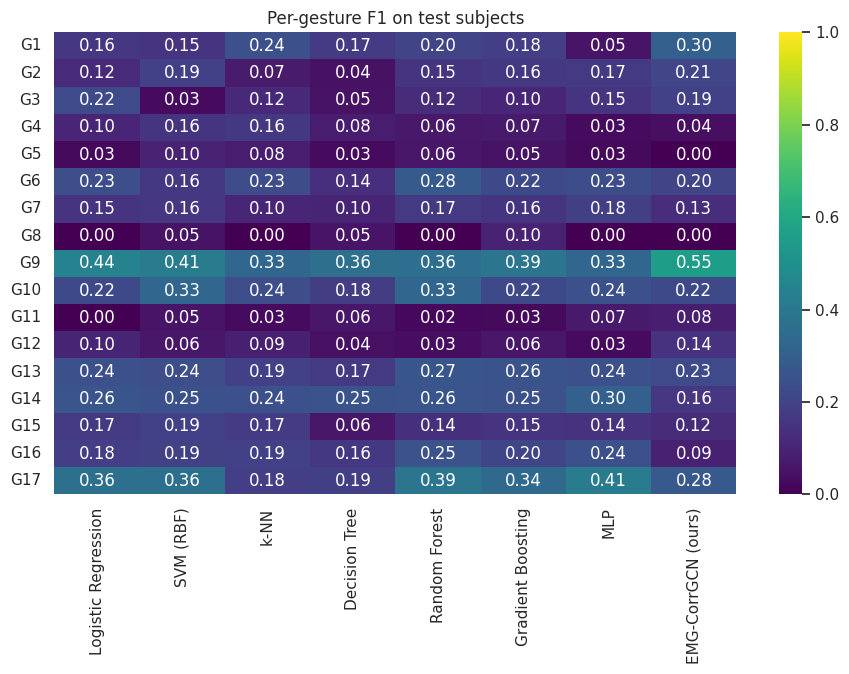

In [16]:
f1_cls = pd.DataFrame({n: f1_score(yte, pr, average=None) for n, pr in preds.items()},
                      index=[f"G{c}" for c in le.classes_])
plt.figure(figsize=(11, 6)); sns.heatmap(f1_cls, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Per-gesture F1 on test subjects"); plt.show()

# Inference time and model size

In [17]:
g = EMGCorrGCN(A_hat, n_cls=len(le.classes_)).eval()       # untrained copy: same cost as the trained model
t0 = time.time()
with torch.no_grad(): g(xte)
cost.loc["EMG-CorrGCN (ours)"] = {"inference_ms_per_window": (time.time() - t0) / len(xte) * 1000,
                                  "model_size_KB": sum(q.numel() for q in g.parameters()) * 4 / 1024}
display(cost.round(3))
print("Model size: pickle size for the sklearn models, parameters x 4 bytes for EMG-CorrGCN.")

,inference_ms_per_window,model_size_KB
Logistic Regression,0.002,2.538
SVM (RBF),0.225,599.279
k-NN,0.053,475.361
Decision Tree,0.001,218.248
Random Forest,0.145,123436.495
Gradient Boosting,0.289,11082.070
MLP,0.002,137.788
EMG-CorrGCN (ours),0.003,29.941


Model size: pickle size for the sklearn models, parameters x 4 bytes for EMG-CorrGCN.


# Conclusion

- **Baseline to beat:** Random Forest, test macro-F1 = 0.182 (random guess = 0.059).
- **EMG-CorrGCN result:** macro-F1 = 0.170 ± 0.003 over 5 seeds. It is slightly worse than the best baseline and similar to Gradient Boosting (0.173) and MLP (0.168). With only 8 test subjects, gaps of 1-2 points are not reliable.
- **Overfitting:** Random Forest and Gradient Boosting reach 100% train accuracy but only about 19% on new subjects, so the main difficulty is subject-to-subject variation, not model capacity. Logistic Regression has the smallest gap (0.107).
- **Channels:** ch11, ch04 and ch09 are the most informative channels (ANOVA F-score), so these are the key nodes of the graph.
- **Why EMG-CorrGCN does not win yet:** only one feature per node (log RMS), one window per repetition, and a graph built from weak correlations (mean r = 0.16). The graph adds little when the node feature is so small.